# Kuş Göçü Veri Seti Görselleştirme Projesi

Veri setinde 10.000 kuşa ait GPS takip kaydı var: tür, bölge, habitat, hava koşulları, uçuş mesafesi/süresi, hız, irtifa, göç başarısı gibi 40'ın üzerinde değişken içeriyor.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


path=r"C:\Users\LENOVO\OneDrive\Masaüstü\Çalışmalar\Lotus AI\Data Visualization Task\Data_Visualization_ Teslim\bird_migration_data.csv"
df = pd.read_csv(path)


In [3]:
df.head()

,Bird_ID,Species,Region,Habitat,Weather_Condition,Migration_Reason,Start_Latitude,Start_Longitude,End_Latitude,End_Longitude,...,Tracking_Quality,Migration_Interrupted,Interrupted_Reason,Tagged_By,Tag_Weight_g,Migration_Success,Recovery_Location_Known,Recovery_Time_days,Observation_Counts,Observation_Quality
0,B1000,Warbler,South America,Grassland,Stormy,Feeding,11.906566,-169.378251,30.377647,-21.366879,...,Excellent,Yes,Storm,Researcher_A,27.0,Failed,No,102,56,Low
1,B1001,Stork,North America,Grassland,Stormy,Breeding,62.301546,-111.475069,39.921092,47.963436,...,Good,Yes,Injury,Researcher_C,14.2,Successful,Yes,118,61,Low
2,B1002,Hawk,South America,Mountain,Stormy,Avoid Predators,87.861164,-78.727327,66.990980,19.448466,...,Fair,No,Lost Signal,Researcher_B,16.1,Failed,No,41,71,High
3,B1003,Warbler,South America,Urban,Stormy,Climate Change,35.770590,153.104341,-49.003145,-157.868744,...,Good,Yes,Lost Signal,Researcher_C,24.4,Successful,No,15,68,Low
4,B1004,Crane,Europe,Urban,Windy,Avoid Predators,-21.611614,106.674824,11.681051,-115.022863,...,Good,No,NaN,Researcher_B,25.8,Failed,Yes,73,67,Moderate


## 1. Box Plot

Burada her kuş türünün kat ettiği uçuş mesafesinin (Flight_Distance_km) dağılımına bakıyorum.

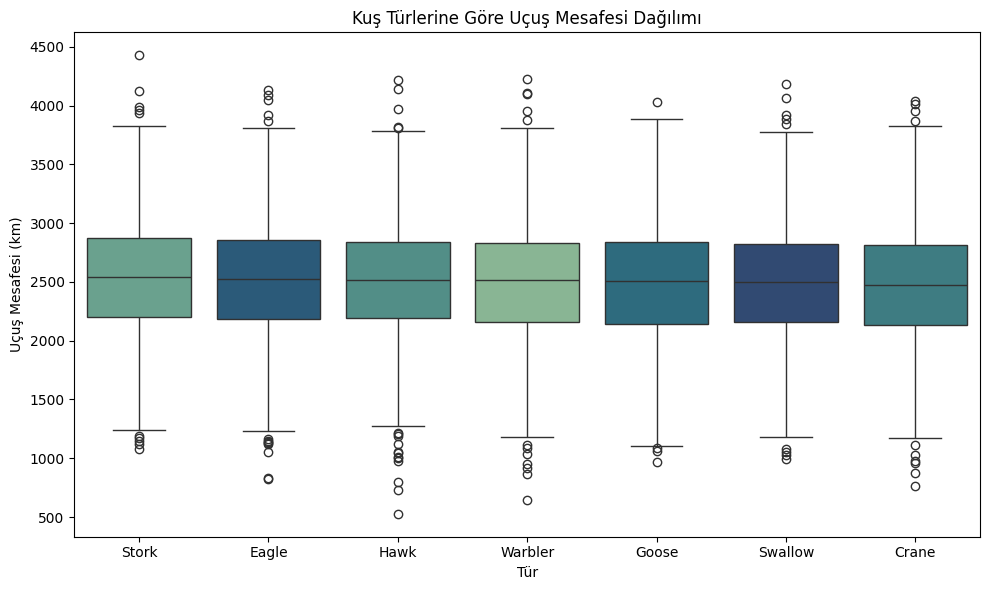

In [4]:
order = df.groupby("Species")["Flight_Distance_km"].median().sort_values(ascending=False).index

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="Species", y="Flight_Distance_km", order=order, hue="Species", palette="crest", legend=False)
plt.title("Kuş Türlerine Göre Uçuş Mesafesi Dağılımı")
plt.xlabel("Tür")
plt.ylabel("Uçuş Mesafesi (km)")
plt.tight_layout()
plt.show()

## 2. Violin Grafik

Burada bölgelere (Region) göre ortalama uçuş hızının (Average_Speed_kmph) dağılımını inceliyorum.

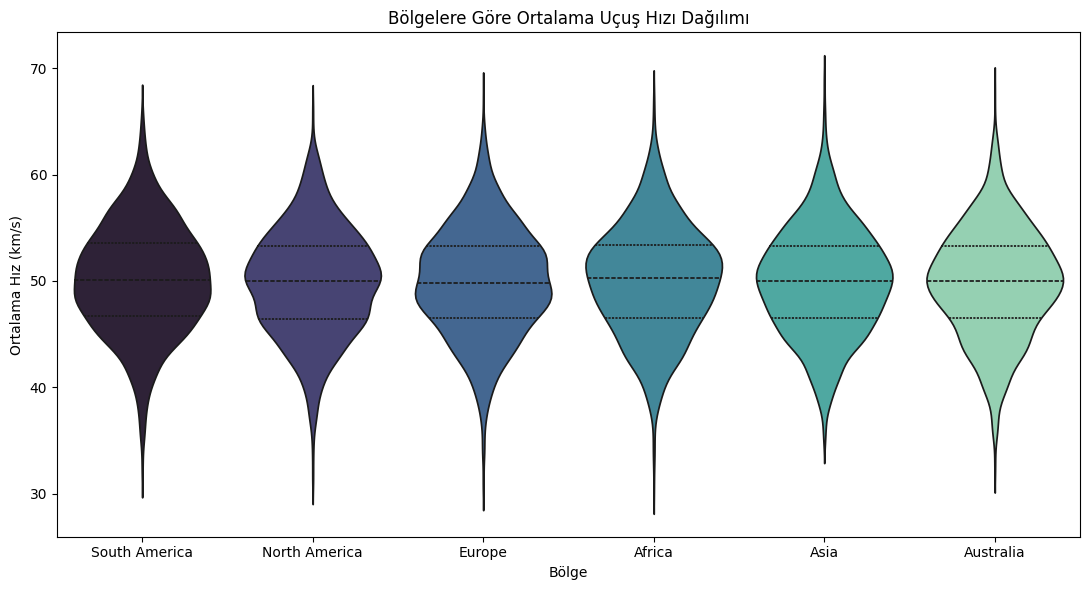

In [5]:
plt.figure(figsize=(11, 6))
sns.violinplot(data=df, x="Region", y="Average_Speed_kmph", hue="Region", palette="mako", legend=False, inner="quartile")
plt.title("Bölgelere Göre Ortalama Uçuş Hızı Dağılımı")
plt.xlabel("Bölge")
plt.ylabel("Ortalama Hız (km/s)")
plt.tight_layout()
plt.show()

## 3. Line Chart

Burada göçün başladığı aya (Migration_Start_Month) göre ortalama uçuş süresinin (Flight_Duration_hours) nasıl değiştiğine bakıyorum.

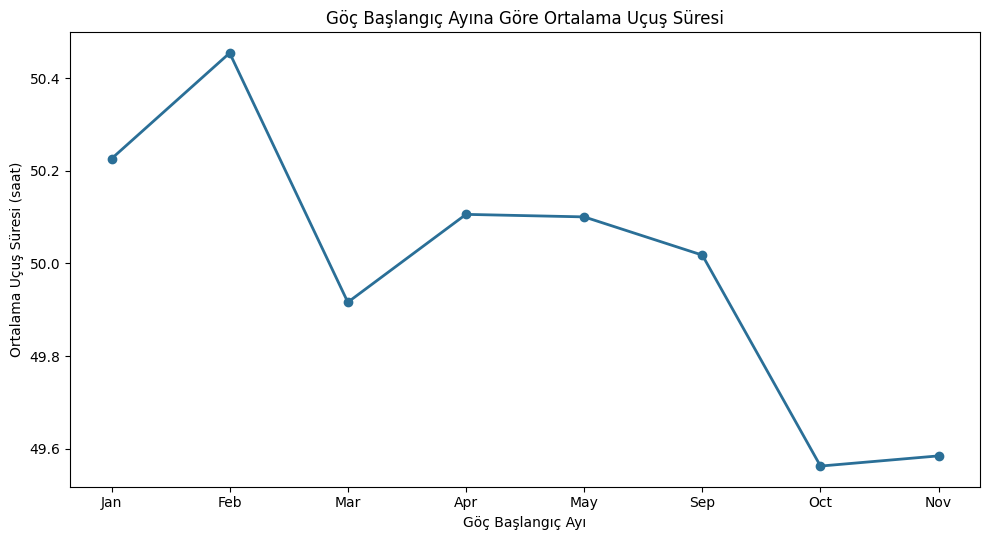

In [6]:
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

monthly = (df.groupby("Migration_Start_Month")["Flight_Duration_hours"]
             .mean()
             .reindex([m for m in month_order if m in df["Migration_Start_Month"].unique()]))

plt.figure(figsize=(10, 5.5))
plt.plot(monthly.index, monthly.values, marker="o", color="#2a6f97", linewidth=2)
plt.title("Göç Başlangıç Ayına Göre Ortalama Uçuş Süresi")
plt.xlabel("Göç Başlangıç Ayı")
plt.ylabel("Ortalama Uçuş Süresi (saat)")
plt.tight_layout()
plt.show()

## 4. Bar Chart

Burada her habitat türünde kaç kuş gözlemlendiğine bakıyorum.

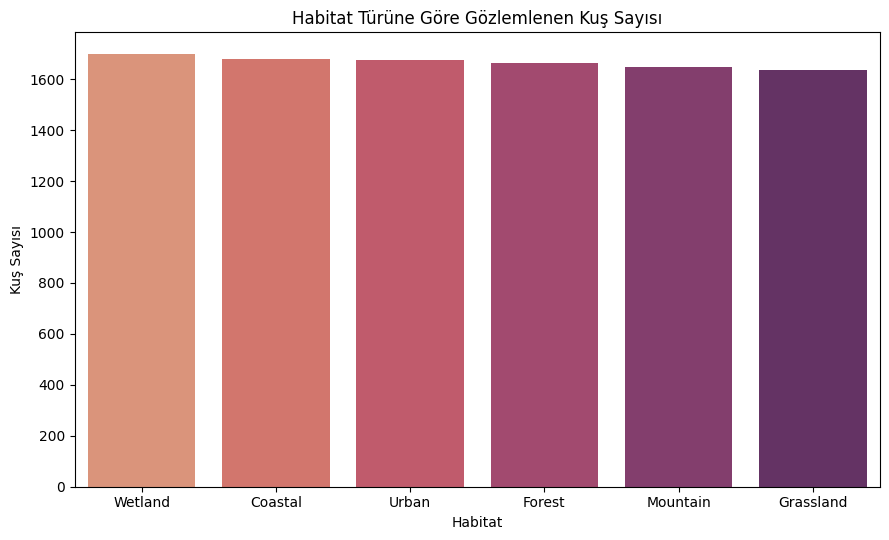

In [7]:
habitat_counts = df["Habitat"].value_counts()

plt.figure(figsize=(9, 5.5))
sns.barplot(x=habitat_counts.index, y=habitat_counts.values, hue=habitat_counts.index, palette="flare", legend=False)
plt.title("Habitat Türüne Göre Gözlemlenen Kuş Sayısı")
plt.xlabel("Habitat")
plt.ylabel("Kuş Sayısı")
plt.tight_layout()
plt.show()

## 5. Pie Chart

Burada göçün başarılı mı yoksa başarısız mı sonuçlandığına (Migration_Success) bakıyorum.

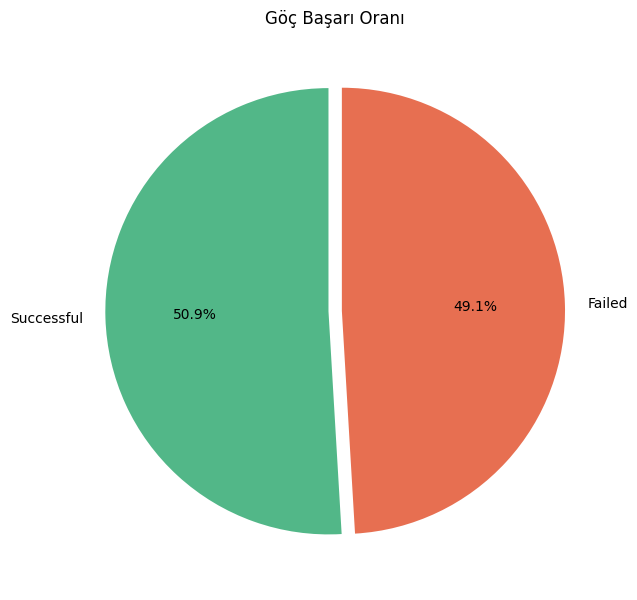

In [8]:
success_counts = df["Migration_Success"].value_counts()

plt.figure(figsize=(6.5, 6.5))
plt.pie(success_counts.values, labels=success_counts.index, autopct="%1.1f%%",
        colors=["#52b788", "#e76f51"], startangle=90, explode=[0.03, 0.03])
plt.title("Göç Başarı Oranı")
plt.tight_layout()
plt.show()